In [12]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mdx2.io import loadobj
from mdx2.report.map_statistics import prepare_table, calc_intensity_statistics

# project directory
project_directory = Path('../processing/results/mac1-east-west')

In [13]:
# calculate isotropic part

def load_merged_calc_stats(dset_root):

    crystal = loadobj(project_directory / dset_root / 'mac1_merge/mdx2/merged.nxs', 'crystal')
    symmetry =  loadobj(project_directory / dset_root / 'mac1_merge/mdx2/merged.nxs', 'symmetry')
    hkl_table =  loadobj(project_directory / dset_root / 'mac1_merge/mdx2/merged.nxs', 'hkl_table')

    df = prepare_table(hkl_table, crystal, symmetry)

    df_stats_excluded = calc_intensity_statistics(df, exclude_bragg=True, bin_width=0.01)
    df_stats = calc_intensity_statistics(df, exclude_bragg=False, bin_width=0.01)
    
    return df_stats, df_stats_excluded

data = {k:load_merged_calc_stats(k) for k in ['chess_20251105','chess_20250924','als_20251015','als_20251125']}


/Users/steve/micromamba/envs/diffuse-analysis/lib/python3.14/site-packages/mdx2/io.py:69: UserWarning: mdx2 version mismatch: file version 1.0.4, installed version 1.0.5
  nxroot = nxload(filename, "r")
/Users/steve/micromamba/envs/diffuse-analysis/lib/python3.14/site-packages/mdx2/io.py:69: UserWarning: mdx2 version mismatch: file version 1.0.4, installed version 1.0.5
  nxroot = nxload(filename, "r")
/Users/steve/micromamba/envs/diffuse-analysis/lib/python3.14/site-packages/mdx2/io.py:69: UserWarning: mdx2 version mismatch: file version 1.0.4, installed version 1.0.5
  nxroot = nxload(filename, "r")


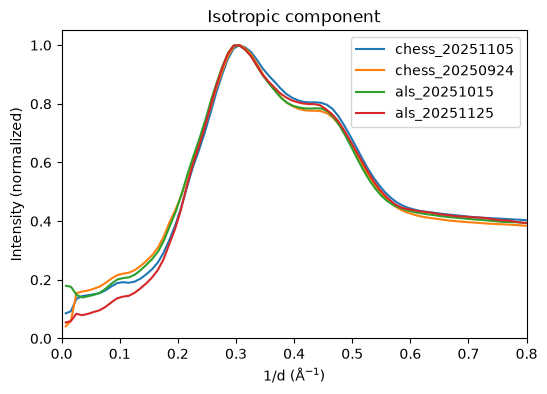

In [14]:
plt.figure(figsize=(6,4))
for k, (df_stats, df_stats_excluded) in data.items():
    normval = np.max(df_stats_excluded['intensity_iso'])
    plt.plot(df_stats_excluded['s'], df_stats_excluded['intensity_iso'] / normval, label=k)
plt.xlabel("1/d (Å$^{-1}$)")
plt.ylabel("Intensity (normalized)")
plt.legend()
plt.ylim(0,1.05)
plt.xlim(0,0.8)
plt.title('Isotropic component')
plt.show()

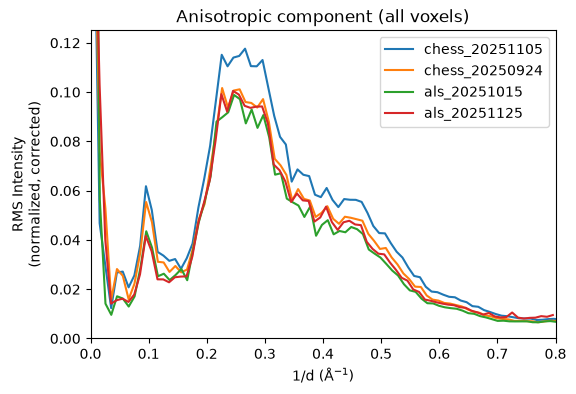

In [15]:
plt.figure(figsize=(6,4))
for k, (df_stats, df_stats_excluded) in data.items():
    normval = np.max(df_stats_excluded['intensity_iso'])
    s = df_stats['s'].array
    ivar = df_stats['intensity_sub_rms'].array**2
    evar = df_stats['intensity_error_rms'].array**2
    signal_var_est = ivar - evar
    signal_var_est[signal_var_est<0] = np.nan # suppress error sqrt(x) when x < 0
    irmscorr = np.sqrt(signal_var_est)
    plt.plot(s, irmscorr / normval, label=k)

plt.xlabel("1/d (Å$^{-1}$)")
plt.ylabel("RMS Intensity\n(normalized, corrected)")
plt.ylim(0,.125)
plt.xlim(0,0.8)
plt.legend()
plt.title('Anisotropic component (all voxels)')
plt.show()

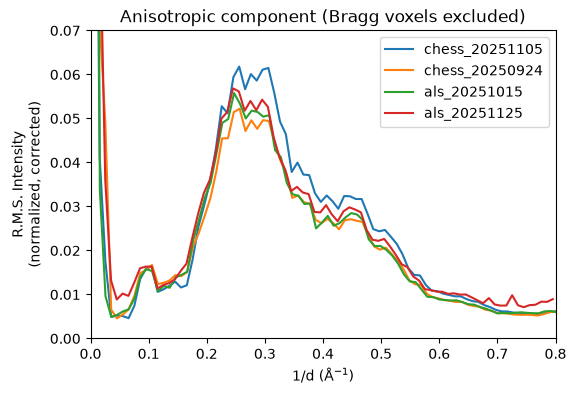

In [16]:
plt.figure(figsize=(6,4))
for k, (df_stats, df_stats_excluded) in data.items():
    normval = np.max(df_stats_excluded['intensity_iso'])
    s = df_stats['s'].array
    ivar = df_stats_excluded['intensity_sub_rms'].array**2
    evar = df_stats_excluded['intensity_error_rms'].array**2
    signal_var_est = ivar - evar
    signal_var_est[signal_var_est<0] = np.nan # suppress error sqrt(x) when x < 0
    irmscorr = np.sqrt(signal_var_est)
    plt.plot(s, irmscorr / normval, label=k)

plt.xlabel("1/d (Å$^{-1}$)")
plt.ylabel("R.M.S. Intensity\n(normalized, corrected)")
plt.ylim(0,0.07)
plt.xlim(0,0.8)
plt.legend()
plt.title('Anisotropic component (Bragg voxels excluded)')
plt.show()

In [17]:
# Dump the curves into csv files for reuse in manuscript figure
for k, (df_stats, df_stats_excluded) in data.items():
    f = df_stats_excluded[['s','intensity_iso','intensity_sub_rms','intensity_error_rms']]
    f = f[(f['s']<=0.81) & (f['s']>0.03)] # trim resolution range
    normval = f['intensity_iso'].max()
    f['intensity_iso']/=normval
    f['intensity_sub_rms']/=normval
    f['intensity_error_rms']/=normval
    ivar = f['intensity_sub_rms'].array**2
    evar = f['intensity_error_rms'].array**2
    signal_var_est = ivar - evar
    signal_var_est[signal_var_est<0] = np.nan # suppress error sqrt(x) when x < 0
    irmscorr = np.sqrt(signal_var_est)
    f['intensity_aniso'] = np.sqrt(signal_var_est)
    f = f.set_index('s');
    f = f[['intensity_iso','intensity_aniso']]
    fn = Path('../figures/source_data')/f'fig2_iso_aniso_{k}.csv'
    print('Writing',fn)
    f.to_csv(fn)

Writing ../figures/source_data/fig2_iso_aniso_chess_20251105.csv
Writing ../figures/source_data/fig2_iso_aniso_chess_20250924.csv
Writing ../figures/source_data/fig2_iso_aniso_als_20251015.csv
Writing ../figures/source_data/fig2_iso_aniso_als_20251125.csv


### Scrape crystal properties from DIALS logs

In [18]:
def scrape_integrate_table(log_root="logs"):
    pats = {
        "Sigma_m (deg.)": r"sigma m:\s*([0-9.]+)",
        "Unit Cell": r"Unit cell:\s*(.+)",
    }
    rows = []
    for p in Path(log_root).glob("*/*/dials/dials.integrate.log"):
        t, ds, run = p.read_text(errors="ignore"), p.parts[-4], p.parts[-3]
        row = {"beamtime": ds, "crystal": run}
        for k, pat in pats.items():
            m = re.search(pat, t, re.M)
            row[k] = m.group(1) if m else None
        rows.append(row)
        # fix the unit cell cloumn
        if row["Unit Cell"] is not None:
            row["Unit Cell"] = tuple(
                float(re.sub(r"\(.*?\)", "", x).strip())
                for x in row["Unit Cell"].split(",")
            )
    return pd.DataFrame(rows).set_index(["beamtime", "crystal"]).sort_index()

integrate_df = scrape_integrate_table(project_directory)
integrate_df

Sigma_m (deg.)  \
beamtime       crystal                  
als_20251015   mac1_10       0.014283   
               mac1_12       0.014095   
               mac1_13       0.014311   
als_20251125   mac1_2        0.014109   
               mac1_4        0.008589   
chess_20250924 mac1_2        0.004160   
               mac1_3        0.003649   
               mac1_5        0.003470   
chess_20251105 mac1_4        0.008870   
               mac1_5        0.007570   

                                                               Unit Cell  
beamtime       crystal                                                    
als_20251015   mac1_10    (89.2747, 89.2747, 40.29875, 90.0, 90.0, 90.0)  
               mac1_12  (89.24147, 89.24147, 40.22104, 90.0, 90.0, 90.0)  
               mac1_13  (89.23695, 89.23695, 40.20218, 90.0, 90.0, 90.0)  
als_20251125   mac1_2     (89.2159, 89.2159, 40.15856, 90.0, 90.0, 90.0)  
               mac1_4   (89.23346, 89.23346, 40.20162, 90.0, 90.0, 90.0)  
chess_20250924 mac1_2   (88.40885, 88.40885, 39.91431, 90.0, 90.0, 90.0)  
               mac1_3   (88.42261, 88.42261, 39.93876, 90.0, 90.0, 90.0)  
               mac1_5   (88.41029, 88.41029, 39.89314, 90.0, 90.0, 90.0)  
chess_20251105 mac1_4   (88.42421, 88.42421, 39.94543, 90.0, 90.0, 90.0)  
               mac1_5   (88.44394, 88.44394, 39.96824, 90.0, 90.0, 90.0)

In [19]:
def scrape_merge_table(log_root="logs"):
    scalar_pats = {
        "Wilson B (Å^2)": r"Wilson B factor\s+([0-9.]+)",
        "Unit Cell": r"Using median unit cell across experiments\s*:\s*\(([^)]+)\)",
    }
    triplet_pats = {
        "I/sigma": r"^I/sigma\s+([0-9.]+)\s+([0-9.]+)\s+([0-9.]+)",
        "Multiplicity": r"^Multiplicity\s+([0-9.]+)\s+([0-9.]+)\s+([0-9.]+)",
    }
    labels = ("overall", "low", "high")
    rows = []

    for p in Path(log_root).glob("*/*/dials/dials.merge.log"):
        t, ds, run = p.read_text(errors="ignore"), p.parts[-4], p.parts[-3]
        row = {"beamtime": ds, "dataset": run}

        for k, pat in scalar_pats.items():
            m = re.search(pat, t, re.M)
            row[(k, "")] = m.group(1) if m else None

        if row[("Unit Cell", "")] is not None:
            row[("Unit Cell", "")] = tuple(float(x.strip()) for x in row[("Unit Cell", "")].split(","))

        if row[("Wilson B (Å^2)", "")] is not None:
            row[("Wilson B (Å^2)", "")] = float(row[("Wilson B (Å^2)", "")])

        for k, pat in triplet_pats.items():
            m = re.search(pat, t, re.M)
            vals = [float(x) for x in m.groups()] if m else [None, None, None]
            for lab, v in zip(labels, vals):
                row[(k, lab)] = v

        rows.append(row)

    df = pd.DataFrame(rows).set_index(["beamtime", "dataset"]).sort_index()
    df.columns = pd.MultiIndex.from_tuples(df.columns)
    return df
    
merge_df = scrape_merge_table(project_directory)
merge_df

Wilson B (Å^2)  \
                                           
beamtime       dataset                     
als_20251015   mac1_merge         13.191   
als_20251125   mac1_merge         12.946   
chess_20250924 mac1_merge         13.182   
chess_20251105 mac1_merge         12.944   

                                                               Unit Cell  \
                                                                           
beamtime       dataset                                                     
als_20251015   mac1_merge   (89.2415, 89.2415, 40.221, 90.0, 90.0, 90.0)   
als_20251125   mac1_merge  (89.2247, 89.2247, 40.1801, 90.0, 90.0, 90.0)   
chess_20250924 mac1_merge  (88.4103, 88.4103, 39.9143, 90.0, 90.0, 90.0)   
chess_20251105 mac1_merge  (88.4341, 88.4341, 39.9568, 90.0, 90.0, 90.0)   

                          I/sigma             Multiplicity              
                          overall    low high      overall   low  high  
beamtime       dataset                                                  
als_20251015   mac1_merge    22.2   96.6  1.0         25.8  31.3   7.6  
als_20251125   mac1_merge    16.2   53.6  0.5         21.1  26.7   2.0  
chess_20250924 mac1_merge    29.0  117.9  1.8         34.2  41.1  12.4  
chess_20251105 mac1_merge    31.7   73.2  3.7         45.7  54.1  14.0